## Лабораторная работа №1 | Вариант 5

Выполнил: Генних А.А. М8О-314БВ-24

### 1. Numpy

In [1]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [2]:
matrix = np.eye(3)
print(matrix)

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


2. Создайте кастомный dtype который описывает цвет состоящий из 4х unsigned bytes(RGBA пиксель)

In [3]:
rgba_dtype = np.dtype([('r', np.ubyte), ('g', np.ubyte), ('b', np.ubyte), ('a', np.ubyte)])
color = np.array((255, 128, 0, 255), dtype=rgba_dtype)
print(color)

(255, 128, 0, 255)


3. Как игнорировать все numpy warnings(не рекомендуем к использованию)?

In [4]:
import warnings
warnings.filterwarnings('ignore')

4. Создайте случайный вектор размера 10 и отсортируйте его

In [5]:
v = np.random.random(10)
v.sort()
print(v)

[0.01945402 0.06385745 0.2182536  0.38999324 0.5522077  0.57953401
 0.66120598 0.66392883 0.67050432 0.83076361]


5. Создайте read-only массив(неизменяемый)

In [6]:
x = np.zeros(5)
x.flags.writeable = False

6. Рассмотрим случайную матрицу размером 10х2, представляющую декартовы координаты, преобразуем их в полярные координаты

In [7]:
Z = np.random.random((10, 2))
X, Y = Z[:, 0], Z[:, 1]
R = np.sqrt(X**2 + Y**2)
Theta = np.arctan2(Y, X)
polar_coords = np.column_stack((R, Theta))
print(polar_coords)

[[0.80629435 0.78216073]
 [1.00650459 1.32439458]
 [0.97217643 1.0153504 ]
 [0.8642561  0.7837064 ]
 [0.74193225 1.44265545]
 [0.76543128 1.30291943]
 [0.94010459 0.91977006]
 [1.19459186 0.93032861]
 [1.26579374 0.72489304]
 [0.73537849 0.93306245]]


7. Создайте структурированный массив с координатами x и y, охватывающий область [0,1]x[0,1]

In [8]:
z = np.zeros(10, dtype=[('x', float), ('y', float)])
z['x'] = np.linspace(0, 1, 10)
z['y'] = np.linspace(0, 1, 10)
print(z)

[(0.        , 0.        ) (0.11111111, 0.11111111)
 (0.22222222, 0.22222222) (0.33333333, 0.33333333)
 (0.44444444, 0.44444444) (0.55555556, 0.55555556)
 (0.66666667, 0.66666667) (0.77777778, 0.77777778)
 (0.88888889, 0.88888889) (1.        , 1.        )]


8. Учитывая два массива X и Y, постройте матрицу Коши $C$ ($C_{ij} =\frac{1}{x_i - y_j}$)

In [9]:
x = np.random.normal(size=(5))
y = np.random.normal(size=(5))

C = 1.0 / (x[:, np.newaxis] - y)
print(C)

[[0.77997595 0.41592025 0.8236209  0.49381155 0.50056828]
 [0.85405278 0.43609011 0.90666119 0.52250398 0.53007473]
 [0.55283745 0.34117278 0.57441224 0.39187669 0.39611983]
 [2.25596426 0.6387794  2.66432599 0.84299787 0.86288122]
 [1.76354479 0.59197659 2.00360744 0.76335124 0.77961866]]


9. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [10]:
Z = np.arange(5, dtype=np.float32)
Z_int = Z.view(np.int32)
print(Z_int)

[         0 1065353216 1073741824 1077936128 1082130432]


10. Как случайно заменить p элементов в 2D массиве?

In [11]:
Z = np.arange(16).reshape(4, 4)
p = 3
flat_indices = np.random.choice(Z.size, p, replace=False)
Z.ravel()[flat_indices] = -1
print(Z)

[[ 0  1  2  3]
 [-1  5  6  7]
 [ 8 -1 10 11]
 [12 -1 14 15]]


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Классический начальный набор данных - данные пассажиров титаника.

Файл: `data.csv`

```
PassangerId - уникальный номер пассажира
Survived - выжил человек или нет
Pclass - класс обслуживания
Name - имя человека, обращение к ней/нему
Sex - пол человека
Age - возраст на момент крушения
SibSp - количество братьев и сестер / супругов на борту "Титаника"
Parch - количество родителей / детей на борту "Титаника"
Ticket - номер билета
Fare - стоимость проезда для пассажиров
Cabin - каюта
Embarked - причал отбытия. C = Cherbourg Q = Queenstown S = Southampton
```

In [12]:
import pandas as pd

In [13]:
# Load dataset here

1. Узнайте сколько было на борту человек

In [14]:
import pandas as pd
df = pd.read_csv('data.csv')

print(len(df))

891


2. Какой медианный и средний возраста пассажиров

In [15]:
print("Средний возраст:", df['Age'].mean())
print("Медианный возраст:", df['Age'].median())

Средний возраст: 29.69911764705882
Медианный возраст: 28.0


3. Посчитайте процент выживаемости детей(до 16 лет) и взрослых

In [16]:
children = df[df['Age'] < 16]
adults = df[df['Age'] >= 16]

print("Процент выживаемости детей:", children['Survived'].mean() * 100)
print("Процент выживаемости взрослых:", adults['Survived'].mean() * 100)

Процент выживаемости детей: 59.036144578313255
Процент выживаемости взрослых: 38.193343898573694


4. Верна ли гипотеза, что женщины и дети сажались в шлюпки первыми и выживали больше?

In [17]:
survived_women = df[df['Sex'] == 'female']['Survived'].mean() * 100
survived_children = children['Survived'].mean() * 100
survived_men = df[(df['Sex'] == 'male') & (df['Age'] >= 16)]['Survived'].mean() * 100

print(f"Женщины: {survived_women:.2f}%")
print(f"Дети: {survived_children:.2f}%")
print(f"Взрослые мужчины: {survived_men:.2f}%")
print("Гипотеза верна")

Женщины: 74.20%
Дети: 59.04%
Взрослые мужчины: 17.43%
Гипотеза верна


5. Зависит ли выживаемость от класса обслуживания?

In [18]:
print(df.groupby('Pclass')['Survived'].mean() * 100)

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


6. Посчитайте средний возраст умерших женщин и мужчин

In [19]:
print(df[df['Survived'] == 0].groupby('Sex')['Age'].mean())

Sex
female    25.046875
male      31.618056
Name: Age, dtype: float64


7. Различается ли процент выживаемости пассажиров с хотя бы одним родственником на борту и одиночек?

In [20]:
df['Has_Relative'] = (df['SibSp'] + df['Parch']) > 0
print(df.groupby('Has_Relative')['Survived'].mean() * 100)

Has_Relative
False    30.353818
True     50.564972
Name: Survived, dtype: float64


8. Различается ли средняя стоимость билета у умерших и выживших пассажиров?

In [21]:
print(df.groupby('Survived')['Fare'].mean())

Survived
0    22.117887
1    48.395408
Name: Fare, dtype: float64


9. Выведите максимальный и минимальный возраст выживших пассажиров во 2 классе обслуживания

In [22]:
pclass2_survived = df[(df['Pclass'] == 2) & (df['Survived'] == 1)]['Age']
print("Максимальный возраст:", pclass2_survived.max())
print("Минимальный возраст:", pclass2_survived.min())

Максимальный возраст: 62.0
Минимальный возраст: 0.67


10. Подтвердите или опровергните гипотезу: молодым мужчинам(от 18 лет) выжить легче, чем более взрослым

In [ ]:
adult_men = df[(df['Sex'] == 'male') & (df['Age'] >= 18)]
young_men = adult_men[(adult_men['Age'] >= 18) & (adult_men['Age'] < 30)]['Survived'].mean() * 100
older_men = adult_men[adult_men['Age'] >= 30]['Survived'].mean() * 100

print(f"Выживаемость молодых мужчин: {young_men:.2f}%")
print(f"Выживаемость взрослых мужчин: {older_men:.2f}%")

Выживаемость молодых мужчин: 15.64%
Выживаемость более взрослых мужчин: 19.44%


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Постройте гистограмму распределения возростов пассажиров

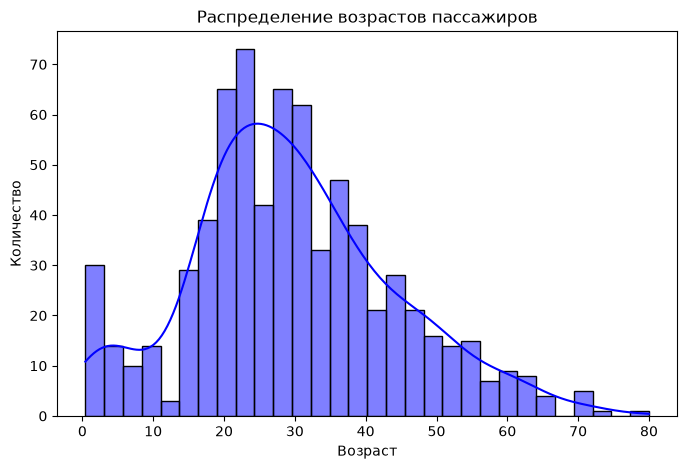

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df['Age'].dropna(), bins=30, kde=True, color='blue')
plt.title('Распределение возрастов пассажиров')
plt.xlabel('Возраст')
plt.ylabel('Количество')
plt.show()

2. Постройте гистограммы распределения цен для пассажиров разных классов

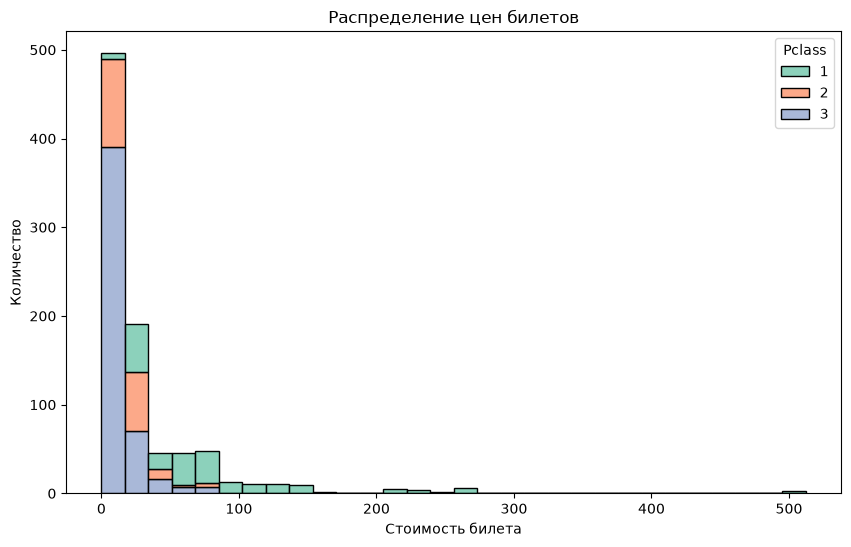

In [31]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='Fare', hue='Pclass', multiple='stack', palette='Set2', bins=30)
plt.title('Распределение цен билетов')
plt.xlabel('Стоимость билета')
plt.ylabel('Количество')
plt.show()

3. Постройте зависимость цены от возраста пассажира

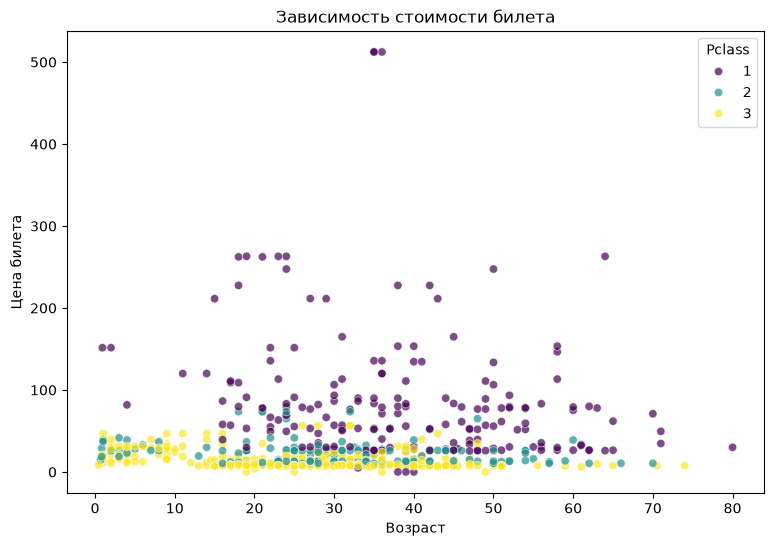

In [34]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='Age', y='Fare', hue='Pclass', palette='viridis', alpha=0.7)
plt.title('Зависимость стоимости билета')
plt.xlabel('Возраст')
plt.ylabel('Цена билета')
plt.show()

4. Постройте box plot отображающий распределение цен на билеты в разных классах

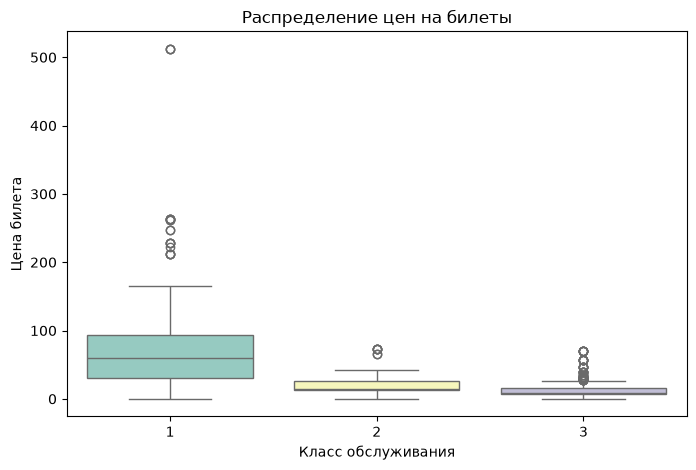

In [35]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Pclass', y='Fare', palette='Set3')
plt.title('Распределение цен на билеты')
plt.xlabel('Класс обслуживания')
plt.ylabel('Цена билета')
plt.show()

5. Визуализируйте распределение долей выживших среди мужчин, женщин и детей(до 16 лет)

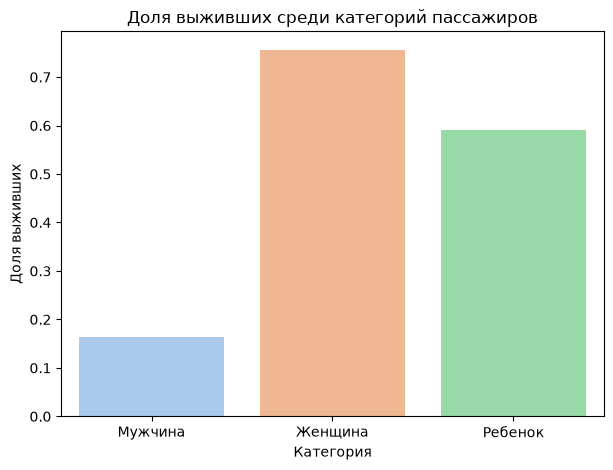

In [38]:
df['Category'] = 'Мужчина'
df.loc[df['Sex'] == 'female', 'Category'] = 'Женщина'
df.loc[df['Age'] < 16, 'Category'] = 'Ребенок'

plt.figure(figsize=(7, 5))
sns.barplot(data=df, x='Category', y='Survived', ci=None, palette='pastel')
plt.title('Доля выживших среди категорий пассажиров')
plt.xlabel('Категория')
plt.ylabel('Доля выживших')
plt.show()

6. Сравните плотности распределения возростов выживших и умерших пассажиров, сделайте выводы

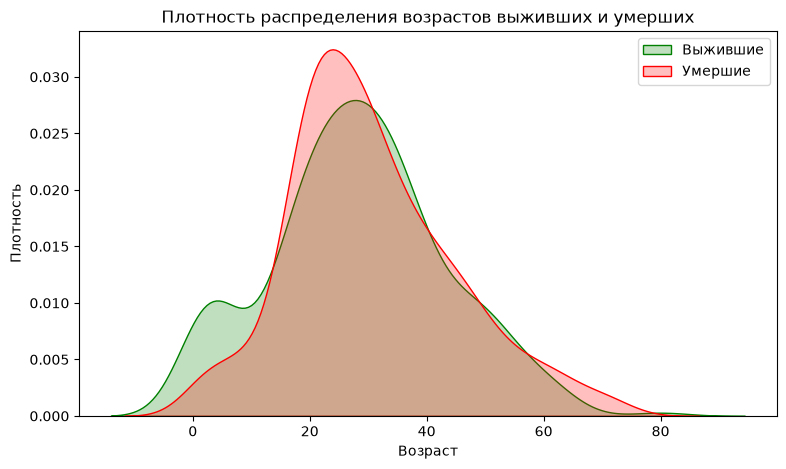

In [29]:
plt.figure(figsize=(9, 5))
sns.kdeplot(data=df[df['Survived'] == 1]['Age'].dropna(), label='Выжившие', fill=True, color='green')
sns.kdeplot(data=df[df['Survived'] == 0]['Age'].dropna(), label='Умершие', fill=True, color='red')
plt.title('Плотность распределения возрастов выживших и умерших')
plt.xlabel('Возраст')
plt.ylabel('Плотность')
plt.legend()
plt.show()

7. Постройте круговую диаграмму отображающую выживаемость мужчин и женщин в разных классах обслуживания(визуализация должна быть интуитивно понятная без объяснений, женщины и мужчины соответствующих классов объеденены визуально в одну группу и 2 подгруппы)*

\* Задание на доп. балл

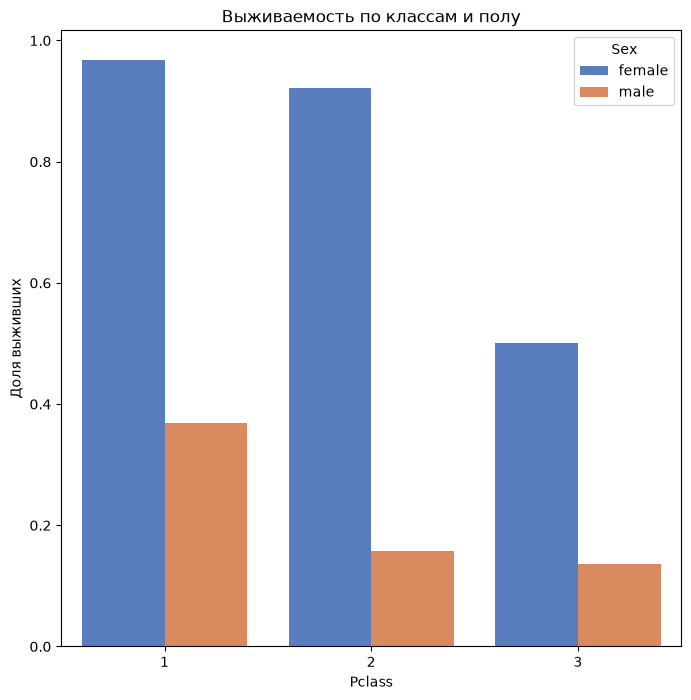

In [39]:
grouped = df.groupby(['Pclass', 'Sex', 'Survived']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(8, 8))
sns.barplot(data=df, x='Pclass', y='Survived', hue='Sex', palette='muted', ci=None, ax=ax)
plt.title('Выживаемость по классам и полу')
plt.ylabel('Доля выживших')
plt.show()